# SimPLe Replication (Pong)

## 1. Environment Setup
Preprocessed Pong env following the paper: frame skip 4, 105x80 RGB frames, 4-frame stack, no sticky actions.

### 1.1 Install and imports

In [ ]:
!pip install -q "gymnasium[atari]" opencv-python-headless

In [ ]:
from dataclasses import dataclass
from collections import Counter

import ale_py
import cv2
import gymnasium as gym
import matplotlib.pyplot as plt
import numpy as np
from gymnasium import spaces

gym.register_envs(ale_py)  # required in Gymnasium 1.x, otherwise "ALE/..." ids are not found

### 1.2 Config
All env settings live here. Defaults match the paper; section numbers are noted in comments.

In [ ]:
@dataclass
class EnvConfig:
    """Environment settings. Defaults follow SimPLe."""
    game: str = "ALE/Pong-v5"
    frame_skip: int = 4               # Sec. 6: each action is repeated 4 times
    frame_stack: int = 4              # Sec. 3: model and policy see the last 4 frames
    obs_height: int = 105             # Sec. 6: 210x160 frames downscaled by a factor of 2
    obs_width: int = 80
    sticky_action_prob: float = 0.0   # main results use deterministic actions
    clip_rewards: bool = True         # reward is predicted as one of {-1, 0, 1}
    frame_pool: str = "max"           # "max" over last 2 raw frames, or "last"; not specified in paper
    seed: int = 0


ENV_CFG = EnvConfig()

### 1.3 Wrappers
`SimPLeEnv` handles frame skip, pooling, downscaling, and reward clipping. `FrameStack` builds the 4-frame input for a policy.

In [ ]:
class SimPLeEnv(gym.Wrapper):
    """Wraps a raw ALE game with SimPLe preprocessing.

    Each step repeats the action `frame_skip` times, sums the rewards,
    pools the last raw frames, and downscales to (obs_height, obs_width).

    Observations are single RGB frames of shape (H, W, 3), dtype uint8.
    """

    def __init__(self, cfg: EnvConfig):
        # frameskip=1 so ALE does not skip on its own; we handle skipping below.
        env = gym.make(
            cfg.game,
            frameskip=1,
            repeat_action_probability=cfg.sticky_action_prob,
        )
        super().__init__(env)
        self.cfg = cfg
        self.observation_space = spaces.Box(
            low=0, high=255, shape=(cfg.obs_height, cfg.obs_width, 3), dtype=np.uint8
        )

    def _process(self, frame: np.ndarray) -> np.ndarray:
        """Downscale a raw (210, 160, 3) frame to (obs_height, obs_width, 3)."""
        # INTER_AREA averages pixel blocks, which keeps small objects like the ball visible.
        return cv2.resize(
            frame, (self.cfg.obs_width, self.cfg.obs_height), interpolation=cv2.INTER_AREA
        )

    def reset(self, **kwargs):
        frame, info = self.env.reset(**kwargs)
        return self._process(frame), info

    def step(self, action: int):
        total_reward = 0.0
        last_two = []  # last 2 raw frames, used for max pooling
        terminated = truncated = False
        info = {}

        for _ in range(self.cfg.frame_skip):
            frame, reward, terminated, truncated, info = self.env.step(action)
            total_reward += reward
            last_two = (last_two + [frame])[-2:]
            if terminated or truncated:
                break

        # Max over the last 2 frames removes flicker where sprites only draw on alternate frames.
        if self.cfg.frame_pool == "max" and len(last_two) == 2:
            pooled = np.maximum(last_two[0], last_two[1])
        else:
            pooled = last_two[-1]

        if self.cfg.clip_rewards:
            total_reward = float(np.sign(total_reward))

        return self._process(pooled), total_reward, terminated, truncated, info

In [ ]:
class FrameStack(gym.Wrapper):
    """Stacks the last `k` frames into one observation.

    Observations have shape (k, 3, H, W), dtype uint8, channels first for PyTorch.
    Oldest frame is index 0, newest is index -1.
    """

    def __init__(self, env: gym.Env, k: int):
        super().__init__(env)
        self.k = k
        h, w, c = env.observation_space.shape
        self.frames = np.zeros((k, c, h, w), dtype=np.uint8)
        self.observation_space = spaces.Box(low=0, high=255, shape=(k, c, h, w), dtype=np.uint8)

    def reset(self, **kwargs):
        frame, info = self.env.reset(**kwargs)
        # Fill the stack with the first frame so the observation is valid from step 0.
        self.frames[:] = frame.transpose(2, 0, 1)
        return self.frames.copy(), info

    def step(self, action: int):
        frame, reward, terminated, truncated, info = self.env.step(action)
        self.frames = np.roll(self.frames, shift=-1, axis=0)
        self.frames[-1] = frame.transpose(2, 0, 1)
        return self.frames.copy(), reward, terminated, truncated, info


def make_env(cfg: EnvConfig = ENV_CFG, stack: bool = False) -> gym.Env:
    """Builds the preprocessed env. Use stack=True when feeding a policy."""
    env = SimPLeEnv(cfg)
    if stack:
        env = FrameStack(env, cfg.frame_stack)
    return env

### 1.4 Sanity checks
Expected: single obs (105, 80, 3), 6 actions, stacked obs (4, 3, 105, 80), ~900-step random episode with mostly 0 and -1 rewards, and the ball visible in the plotted frames.

single obs: (105, 80, 3) uint8
actions: Discrete(6) ['NOOP', 'FIRE', 'RIGHT', 'LEFT', 'RIGHTFIRE', 'LEFTFIRE']
stacked obs: (4, 3, 105, 80)
episode length: 902, rewards: {0.0: 880, -1.0: 21, 1.0: 1}


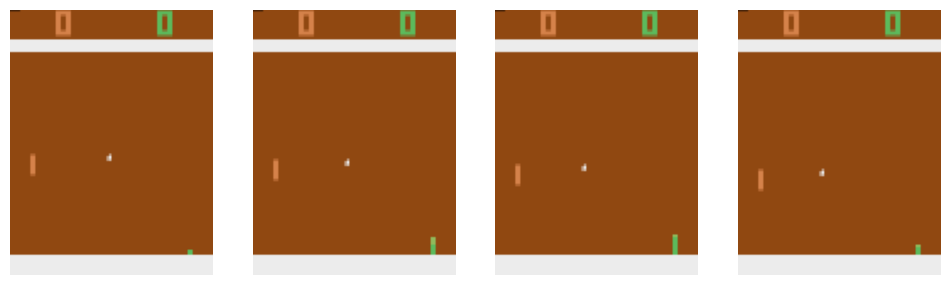

In [ ]:
# Shapes and action space
env = make_env()
obs, _ = env.reset(seed=ENV_CFG.seed)
print("single obs:", obs.shape, obs.dtype)
print("actions:", env.action_space, env.unwrapped.get_action_meanings())

stacked, _ = make_env(stack=True).reset(seed=ENV_CFG.seed)
print("stacked obs:", stacked.shape)

# One random episode: length, reward counts, and frames where the ball is visible
rng = np.random.default_rng(ENV_CFG.seed)
obs, _ = env.reset(seed=ENV_CFG.seed)
rewards, ball_frames, steps = Counter(), [], 0
done = False
while not done:
    obs, r, terminated, truncated, _ = env.step(int(rng.integers(env.action_space.n)))
    done = terminated or truncated
    rewards[r] += 1
    steps += 1
    # Ball is near-white; look for it inside the play area only (rows 17-95 skip score and walls).
    if (obs[17:96].min(axis=2) > 180).any() and len(ball_frames) < 4:
        ball_frames.append(obs)

print(f"episode length: {steps}, rewards: {dict(rewards)}")

fig, axes = plt.subplots(1, len(ball_frames), figsize=(12, 4))
for ax, f in zip(axes, ball_frames):
    ax.imshow(f)
    ax.axis("off")
plt.show()

### 1.5 Interface notes (for the dataset code)
- `env = make_env()` returns single frames; `make_env(stack=True)` returns 4-frame stacks for a policy.
- `reset()` -> `(obs, info)`; `step(a)` -> `(obs, reward, terminated, truncated, info)` (standard Gymnasium).
- Single obs: `(105, 80, 3)` uint8 RGB. Stacked obs: `(4, 3, 105, 80)` uint8, oldest frame first.
- Actions: `Discrete(6)` = NOOP, FIRE, RIGHT, LEFT, RIGHTFIRE, LEFTFIRE.
- Rewards are clipped to {-1, 0, 1}. One step = 4 game frames.
- Store single frames in the buffer, not stacks. Rebuild stacks at sampling time.
- Do not change EnvConfig values without telling the team; the world model depends on them.

## 2. Data Collection

### 2.1 Extra imports

In [ ]:
from dataclasses import asdict, replace
import json
import os

### 2.2 Dataset config and replay buffer
Shapes are read from the environment, not from `DataConfig`, so changing `EnvConfig` changes the dataset automatically. `ReplayBuffer` stores single frames and rebuilds the stacks when sampling; at an episode start the missing older frames repeat the first frame, exactly like `FrameStack.reset()`. Episodes are split into train and held-out by episode.

In [ ]:
@dataclass
class DataConfig:
    """Dataset settings. Shapes (stack size, frame size, channels) are NOT set here:
    they are read from the env, so changing EnvConfig automatically changes the dataset."""
    steps_per_iter: int = 6_400      # Sec. 6: 6400 real interactions per loop iteration
    n_iters: int = 16                # 16 x 6400 = 102,400 real steps in total (the budget)
    holdout_every: int = 10          # every 10th episode goes to the held-out split
    extra_slots: int = 2_000         # room for the +1 frame per episode (~120 episodes needed)
    save_dir: str = "data"           # point this at Google Drive in Colab so it survives disconnects
    seed: int = 0

    @property
    def budget(self) -> int:
        return self.steps_per_iter * self.n_iters

    @property
    def capacity(self) -> int:
        return self.budget + self.extra_slots


DATA_CFG = DataConfig()

# EnvConfig fields that change what the data looks like. A saved dataset is only reusable
# if all of these match (seed is allowed to differ).
_DATA_DEFINING = ["game", "frame_skip", "frame_stack", "obs_height", "obs_width",
                  "sticky_action_prob", "clip_rewards", "frame_pool"]


class ReplayBuffer:
    """Dataset D: real transitions only, stored as single frames. Stacks are rebuilt when sampling.

    Each episode occupies T+1 consecutive slots: frames f_0 (reset) ... f_T (last).
    Transition i is (stack ending at f_i, action[i]) -> (f_{i+1}, reward[i]).
    Frames are stored as (C, H, W) uint8; shapes come from the env, not from hard-coded numbers.
    """

    def __init__(self, obs_shape: tuple, n_actions: int, data_cfg: DataConfig, env_meta: dict | None = None):
        k, c, h, w = obs_shape                      # shape of ONE stacked observation
        n = data_cfg.capacity
        self.k, self.cap, self.n_actions = k, n, n_actions
        self.budget = data_cfg.budget
        self.holdout_every = data_cfg.holdout_every
        self.env_meta = env_meta or {}
        self.frames = np.zeros((n, c, h, w), dtype=np.uint8)
        self.action = np.zeros(n, dtype=np.int64)
        self.reward = np.zeros(n, dtype=np.float32)
        self.ep_start = np.zeros(n, dtype=np.int64)   # index of first frame of this frame's episode
        self.has_trans = np.zeros(n, dtype=bool)      # True if an action/next frame exist for slot i
        self.holdout = np.zeros(n, dtype=bool)        # True if the episode is in the held-out split
        self.size = 0          # slots used
        self.steps = 0         # real agent steps taken = the 100K budget counter
        self.n_episodes = 0

    @classmethod
    def from_env(cls, env: gym.Env, data_cfg: DataConfig, env_cfg: "EnvConfig | None" = None):
        """Builds a buffer whose shapes match `env` (must be make_env(stack=True))."""
        shape = env.observation_space.shape
        assert len(shape) == 4, "use make_env(stack=True): expected obs shape (k, C, H, W)"
        meta = asdict(env_cfg) if env_cfg is not None else {}
        return cls(shape, env.action_space.n, data_cfg, meta)

    # ---- writing ----
    def start_episode(self, frame: np.ndarray):
        """frame: (C, H, W) uint8, the first observation after reset."""
        assert self.size < self.cap, "buffer full"
        i = self.size
        self.frames[i] = frame
        self.ep_start[i] = i
        self.holdout[i] = (self.n_episodes % self.holdout_every) == self.holdout_every - 1
        self.size += 1
        self.n_episodes += 1

    def add_step(self, action: int, reward: float, next_frame: np.ndarray):
        """Record the transition out of the latest frame, and the next frame."""
        assert self.size < self.cap, "buffer full"
        assert 0 <= action < self.n_actions, f"bad action {action}"
        i = self.size - 1
        self.action[i], self.reward[i], self.has_trans[i] = action, reward, True
        j = self.size
        self.frames[j] = next_frame
        self.ep_start[j] = self.ep_start[i]
        self.holdout[j] = self.holdout[i]
        self.size += 1
        self.steps += 1

    # ---- reading ----
    def _stack(self, idx: np.ndarray) -> np.ndarray:
        """Stacks ending at idx -> (B, k, C, H, W) and b is batch size. Frames before the episode start
        repeat the first frame, exactly like FrameStack.reset()."""
        offs = idx[:, None] + np.arange(-self.k + 1, 1)[None, :]
        offs = np.maximum(offs, self.ep_start[idx][:, None])
        return self.frames[offs]

    def _valid(self, split: str) -> np.ndarray:
        assert split in ("train", "holdout")
        m = self.has_trans[: self.size]
        h = self.holdout[: self.size]
        return np.flatnonzero(m & (h if split == "holdout" else ~h))

    def sample_batch(self, batch_size: int, rng: np.random.Generator, split: str = "train"):
        """One-step batch: (stack (B,k,C,H,W), action (B,), next_frame (B,C,H,W), reward (B,))."""
        idx = rng.choice(self._valid(split), size=batch_size)
        return self._stack(idx), self.action[idx], self.frames[idx + 1], self.reward[idx]

    def sample_start_states(self, n: int, rng: np.random.Generator, split: str = "train"):
        """Real stacks that start imagined rollouts (Algorithm 1, step 3): (n,k,C,H,W)."""
        idx = rng.choice(self._valid(split), size=n)
        return self._stack(idx)

    def sample_sequences(self, n: int, length: int, rng: np.random.Generator, split: str = "holdout"):
        """Real multi-step sequences for prediction error vs. rollout length.
        Returns start stack (n,k,C,H,W), actions (n,L), next frames (n,L,C,H,W), rewards (n,L)."""
        cand = self._valid(split)
        cand = cand[cand + length - 1 < self.size]
        cand = cand[self.ep_start[cand] == self.ep_start[cand + length - 1]]
        cand = cand[self.has_trans[cand + length - 1]]   # whole window lies inside one episode
        assert len(cand) > 0, "no sequence of this length in the split"
        idx = rng.choice(cand, size=n)
        win = idx[:, None] + np.arange(length)[None, :]
        return self._stack(idx), self.action[win], self.frames[win + 1], self.reward[win]

    def summary(self) -> str:
        r = self.reward[: self.size][self.has_trans[: self.size]]
        mem = self.frames[: self.size].nbytes / 1e9
        return (f"steps={self.steps} episodes={self.n_episodes} slots={self.size}/{self.cap} "
                f"train={len(self._valid('train'))} holdout={len(self._valid('holdout'))} "
                f"rewards(-1/0/+1)={int((r<0).sum())}/{int((r==0).sum())}/{int((r>0).sum())} "
                f"frames={mem:.2f} GB")

    # ---- saving and loading ----
    def save(self, path: str):
        """Saves the used part of the buffer plus the env settings that produced it."""
        os.makedirs(os.path.dirname(path) or ".", exist_ok=True)
        n = self.size
        np.savez_compressed(
            path, frames=self.frames[:n], action=self.action[:n], reward=self.reward[:n],
            ep_start=self.ep_start[:n], has_trans=self.has_trans[:n], holdout=self.holdout[:n],
            counters=np.array([self.steps, self.n_episodes, self.k, self.n_actions]),
            env_meta=np.array(json.dumps(self.env_meta)),
        )

    @classmethod
    def load(cls, path: str, data_cfg: DataConfig, env_cfg: "EnvConfig | None" = None):
        """Loads a saved buffer. Refuses to load data made with different env settings."""
        d = np.load(path, allow_pickle=False)
        saved = json.loads(str(d["env_meta"]))
        if env_cfg is not None and saved:
            now = asdict(env_cfg)
            bad = {k: (saved.get(k), now.get(k)) for k in _DATA_DEFINING if saved.get(k) != now.get(k)}
            assert not bad, f"saved data was made with different env settings (saved, current): {bad}"
        n = len(d["action"])
        _, c, h, w = d["frames"].shape
        steps, n_eps, k, n_actions = (int(x) for x in d["counters"])
        buf = cls((k, c, h, w), n_actions, data_cfg, saved)
        assert n <= buf.cap, "saved data larger than the current capacity; raise DataConfig.n_iters"
        buf.frames[:n], buf.action[:n], buf.reward[:n] = d["frames"], d["action"], d["reward"]
        buf.ep_start[:n], buf.has_trans[:n], buf.holdout[:n] = d["ep_start"], d["has_trans"], d["holdout"]
        buf.size, buf.steps, buf.n_episodes = n, steps, n_eps
        return buf


def to_torch(batch, device="cpu"):
    """Converts a sample_batch result to float tensors scaled to [0, 1] (stacks/frames),
    long actions and float rewards. Torch is imported here so the buffer works without it."""
    import torch
    stack, action, next_frame, reward = batch
    return (torch.from_numpy(stack).to(device).float() / 255.0,
            torch.from_numpy(action).to(device),
            torch.from_numpy(next_frame).to(device).float() / 255.0,
            torch.from_numpy(reward).to(device))

### 2.3 Collecting real data
`collect` plays real steps with a policy and writes them to the buffer. It needs the stacked env (the policy takes stacks), but stores only the newest frame of each stack. It stops with an error if it would exceed the 100K budget.

In [ ]:
def collect(env: gym.Env, policy, n_steps: int, buffer: ReplayBuffer, seed: int | None = None):
    """Plays `n_steps` real agent steps with `policy` and writes them to `buffer`.

    env must be make_env(cfg, stack=True). policy maps one stack (k, C, H, W) to an int action.
    Refuses to exceed the real-step budget. Returns finished-episode returns (for monitoring).
    """
    assert buffer.steps + n_steps <= buffer.budget, \
        f"would exceed the real-step budget ({buffer.steps}+{n_steps} > {buffer.budget})"
    returns, ep_ret, taken = [], 0.0, 0
    obs, _ = env.reset(seed=seed)
    buffer.start_episode(obs[-1])
    while taken < n_steps:
        a = int(policy(obs))
        obs, r, terminated, truncated, _ = env.step(a)
        buffer.add_step(a, r, obs[-1])
        ep_ret += r
        taken += 1
        if terminated or truncated:
            returns.append(ep_ret)
            ep_ret = 0.0
            if taken < n_steps:
                obs, _ = env.reset()
                buffer.start_episode(obs[-1])
    return returns

### 2.4 Sanity checks
Expected: the step counter equals 1000, the rebuilt stacks match what the policy saw, and the plotted pair shows a small difference (ball and paddles moved).

steps=1000 episodes=2 slots=1002/3000 train=1000 holdout=0 rewards(-1/0/+1)=22/977/1 frames=0.03 GB
finished-episode returns: [-20.0]
stack check passed


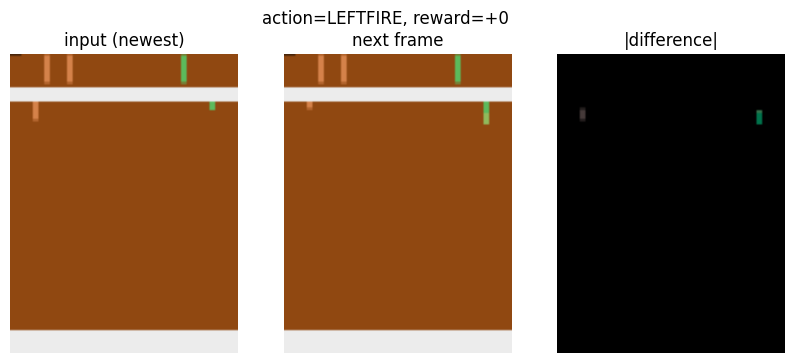

In [ ]:
# Small throwaway buffer: does NOT touch the real 100K budget
check_env = make_env(ENV_CFG, stack=True)
check_cfg = replace(DATA_CFG, steps_per_iter=1000, n_iters=1)
check_buf = ReplayBuffer.from_env(check_env, check_cfg, ENV_CFG)
rng = np.random.default_rng(DATA_CFG.seed)
seen = []  # the stacks the policy actually received

def random_policy(obs):
    seen.append(obs.copy())
    return int(rng.integers(check_env.action_space.n))

ep_returns = collect(check_env, random_policy, 1000, check_buf, seed=DATA_CFG.seed)
print(check_buf.summary())
print("finished-episode returns:", ep_returns)

# 1. Stacks rebuilt from single frames must equal what the policy saw (incl. episode starts)
idx = np.flatnonzero(check_buf.has_trans[: check_buf.size])
rebuilt = check_buf._stack(idx)
assert all((rebuilt[i] == seen[i]).all() for i in range(1000)), "stack mismatch with FrameStack"
print("stack check passed")

# 2. One sampled transition: newest input frame, next frame, and their difference
stack, action, next_frame, reward = check_buf.sample_batch(1, rng)
cur, nxt = stack[0, -1].transpose(1, 2, 0), next_frame[0].transpose(1, 2, 0)
diff = np.abs(nxt.astype(int) - cur.astype(int)).astype(np.uint8)
meanings = check_env.unwrapped.get_action_meanings()
fig, axes = plt.subplots(1, 3, figsize=(10, 4))
for ax, im, title in zip(axes, [cur, nxt, diff], ["input (newest)", "next frame", "|difference|"]):
    ax.imshow(im); ax.set_title(title); ax.axis("off")
plt.suptitle(f"action={meanings[action[0]]}, reward={reward[0]:+.0f}")
plt.show()

### 2.5 Iteration 1: random data, then save
The paper's first 6,400 steps come from a random policy.

In [ ]:
# Iteration 1: random policy. Later iterations call collect() again with the latest PPO policy.
stacked_env = make_env(ENV_CFG, stack=True)
buffer = ReplayBuffer.from_env(stacked_env, DATA_CFG, ENV_CFG)
rng = np.random.default_rng(DATA_CFG.seed)

def random_policy(obs):
    return int(rng.integers(stacked_env.action_space.n))

collect(stacked_env, random_policy, DATA_CFG.steps_per_iter, buffer, seed=DATA_CFG.seed)
print(buffer.summary())

# Save after every iteration (use a Google Drive path for DATA_CFG.save_dir in Colab)
buffer.save(f"{DATA_CFG.save_dir}/buffer_iter00.npz")

# Teammates (or a restarted session) can reload it without playing again:
# buffer = ReplayBuffer.load(f"{DATA_CFG.save_dir}/buffer_iter00.npz", DATA_CFG, ENV_CFG)

steps=6400 episodes=7 slots=6407/104400 train=6400 holdout=0 rewards(-1/0/+1)=142/6254/4 frames=0.16 GB


## 2.6 Interface notes for the model and PPO code
**Everything is derived from `make_env(ENV_CFG, stack=True)`**, so if `EnvConfig` changes (frame stack, resolution, game, ...) the buffer adapts. Nothing in the dataset code hard-codes 4, 105, 80, 3 or 6.

- `buffer = ReplayBuffer.from_env(stacked_env, DATA_CFG, ENV_CFG)`: one buffer per run. `buffer.steps` is the real-step counter; `collect` refuses to go past `DATA_CFG.budget` (102,400).
- `collect(stacked_env, policy, n_steps, buffer)`: `policy` maps one stack `(k, C, H, W)` uint8 to an int action. Random in iteration 1, the latest PPO policy afterwards.
- **For the world model:** `buffer.sample_batch(B, rng)` returns NumPy `(stack (B,k,C,H,W), action (B,), next_frame (B,C,H,W), reward (B,))`. `to_torch(batch, device)` converts it to float tensors in [0, 1]. Do not train on `split="holdout"`.
- **For PPO:** `buffer.sample_start_states(n, rng)` returns real stacks to start imagined rollouts (about 50 steps each). PPO itself trains on imagined rollouts, not on the buffer.
- **For evaluation:** `buffer.sample_sequences(n, L, rng, split="holdout")` returns start stack, actions `(n,L)`, next frames `(n,L,C,H,W)`, rewards `(n,L)` to measure prediction error vs. rollout length.
- `buffer.save(path)` / `ReplayBuffer.load(path, DATA_CFG, ENV_CFG)`. Loading **refuses** data made with different env settings (game, frame skip, stack, size, sticky actions, reward clipping, pooling), so old files can never silently mix with a new config.
- Only real-game steps go into the buffer. Never add imagined frames. Real-game evaluation for Experiment A must use its own counter, not `collect`.
- Held-out episodes (every 10th) still count toward the 100K budget.